# 04 — Análisis de errores e interpretabilidad (Lending Club)

**Proyecto final de Machine Learning — Entrega final**

Se analiza el **modelo final** (elegido por validación cruzada temporal en
`03_modelos.ipynb`) sobre el **test out-of-time**: dónde se equivoca, por qué,
qué variables usa y si su desempeño es desigual entre grupos de solicitantes.
Todas las cifras salen de `outputs/predictions_test.parquet` y
`outputs/models/final_model.joblib`, generados por `python -m src.train`.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import RANDOM_SEED, TARGET
from src import evaluate as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
np.random.seed(RANDOM_SEED)

import os
OUT = Path(os.environ.get("ML_OUT", ROOT / "outputs"))            # resultados de `python -m src.train`
FIG = Path(os.environ.get("ML_FIG", ROOT / "reports" / "figures"))

In [2]:
import joblib
from sklearn.metrics import roc_auc_score
from src.train import to_model_frame
from src.features import NUM_COLS_FINAL, CAT_COLS_FINAL

metrics = json.load(open(OUT / "metrics.json"))
bundle = joblib.load(OUT / "models" / "final_model.joblib")
final_name, thr = bundle["name"], bundle["threshold"]
model = bundle["model"]

preds = pd.read_parquet(OUT / "predictions_test.parquet")
preds["score"] = preds[f"p_{final_name}"]
preds["pred"] = (preds["score"] >= thr).astype(int)
y = preds[TARGET]
print(f"Modelo final: {final_name} | umbral operativo = {thr:.3f} | n test = {len(preds):,}")
print(f"ROC-AUC test = {roc_auc_score(y, preds['score']):.4f}")

Modelo final: hist_gradient_boosting | umbral operativo = 0.167 | n test = 280,245
ROC-AUC test = 0.7025


## 1. Separación de scores y tipos de error

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, lbl, col in [(0, "Pagado (0)", "#55A868"), (1, "Default (1)", "#C44E52")]:
    sns.histplot(preds.loc[y == k, "score"], bins=60, stat="density", ax=ax,
                 color=col, alpha=.45, label=lbl)
ax.axvline(thr, color="black", ls="--", lw=1.2, label=f"umbral = {thr:.3f}")
ax.set_xlabel("Probabilidad de default predicha")
ax.set_title("Distribución del score por resultado real (test)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "30_score_distribution.png", dpi=120); plt.show()

preds["tipo"] = np.select(
    [(preds.pred == 1) & (y == 1), (preds.pred == 1) & (y == 0),
     (preds.pred == 0) & (y == 1)], ["VP", "FP", "FN"], "VN")
preds["tipo"].value_counts(normalize=True).rename("proporción").to_frame()

/var/folders/x3/x63pd0m12l35bhc94445mwsw0000gn/T/ipykernel_14249/960826242.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(FIG / "30_score_distribution.png", dpi=120); plt.show()


,proporción
tipo,
VN,0.3755
FP,0.3614
VP,0.2039
FN,0.0591


In [4]:
# Tabla por deciles de score: ¿el riesgo crece de forma monótona?
preds["decil"] = pd.qcut(preds["score"], 10, labels=range(1, 11))
dec = preds.groupby("decil", observed=True).agg(
    n=("score", "size"), score_medio=("score", "mean"),
    tasa_default=(TARGET, "mean"))
dec["pct_defaults_en_este_decil_o_superiores"] = (
    preds.groupby("decil", observed=True)[TARGET].sum()[::-1].cumsum()[::-1] / y.sum())
dec

,n,score_medio,tasa_default,pct_defaults_en_este_decil_o_superiores
decil,,,,
1,28025,0.0403,0.0552,1.0000
2,28024,0.0781,0.1118,0.9790
3,28025,0.1108,0.1528,0.9365
4,28024,0.1414,0.1964,0.8784
5,28025,0.1713,0.2304,0.8037
6,28024,0.2023,0.2701,0.7161
7,28024,0.2379,0.3173,0.6135
8,28025,0.2837,0.3606,0.4929
9,28024,0.3523,0.4189,0.3558


**Lectura:**
- El riesgo **crece de forma monótona por decil**: del 5.5% de default en el decil 1 al 51.7% en el decil 10. El modelo ordena bien aunque la separación entre clases sea moderada, y los histogramas de ambas clases se solapan mucho.
- El 30% de préstamos con score más alto (deciles 8–10) concentra el **49% de los defaults**. El 20% de menor riesgo (deciles 1–2) contiene solo el 6%.
- Al umbral operativo, el error dominante es el **falso positivo** (36% de los préstamos): buenos pagadores marcados como riesgo. Los falsos negativos son el 5.9%, pero representan el 22% de los defaults.

## 2. Errores por segmentos

In [5]:
preds["issue_q"] = preds["issue_dt"].dt.to_period("Q").astype(str)
preds["ingreso_quintil"] = pd.qcut(preds["annual_inc"], 5,
                                   labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
seg_files = {}
segments = ["grade", "term", "home_ownership", "verification_status",
            "ingreso_quintil", "emp_length", "purpose", "issue_q"]
seg_tables = {}
for s in segments:
    t = ev.segment_report(preds, s, TARGET, "score", thr)
    if s == "emp_length":
        order = ["< 1 year", "1 year"] + [f"{i} years" for i in range(2, 10)] + ["10+ years", "Desconocido"]
        t = t.set_index(s).reindex([o for o in order if o in set(t[s])]).reset_index()
    elif s == "purpose":
        t = t.sort_values("tasa_default_real")
    seg_tables[s] = t
    ev.plot_segment(t, s, FIG / f"31_segment_{s}.png")
pd.concat({s: t.set_index(s) for s, t in seg_tables.items()}).to_csv(OUT / "segment_errors.csv")

,grade,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,A,45107,0.087,0.057,0.669,0.008,0.311,0.002,-0.029
1,B,77266,0.191,0.139,0.622,0.375,0.278,0.257,-0.051
2,C,88426,0.298,0.231,0.619,0.879,0.328,0.799,-0.068
3,D,44345,0.382,0.316,0.607,0.984,0.390,0.965,-0.066
4,E,17023,0.443,0.425,0.607,1.000,0.444,0.997,-0.018
5,F,5405,0.507,0.532,0.607,1.000,0.507,1.000,0.025
6,G,2673,0.541,0.533,0.584,1.000,0.541,1.000,-0.009


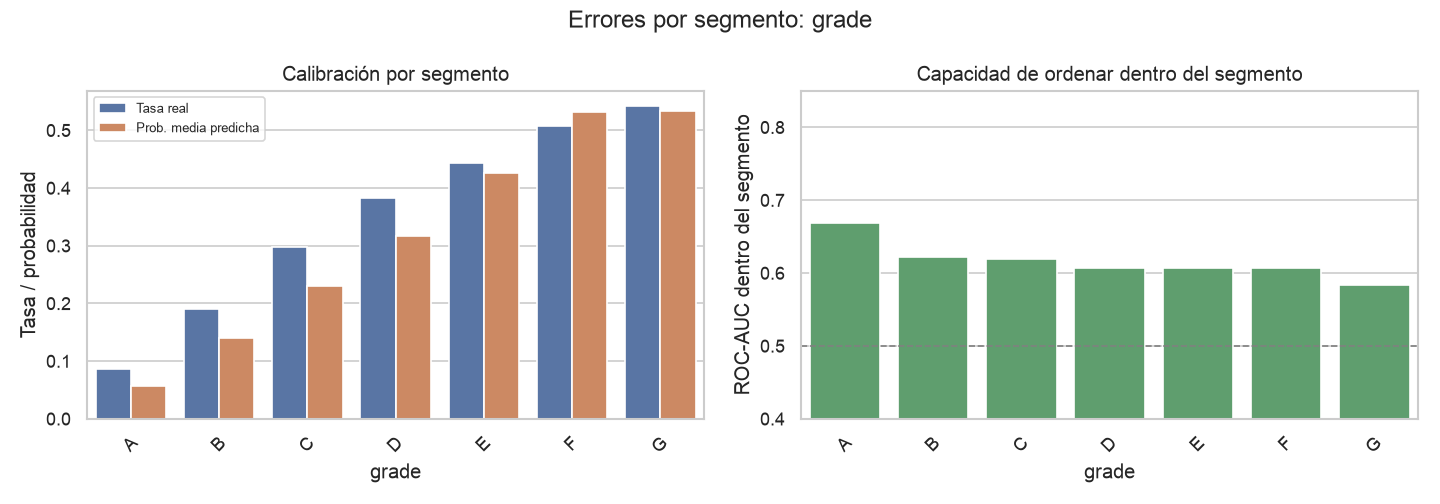

,issue_q,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,2016Q4,39381,0.265,0.218,0.689,0.791,0.348,0.603,-0.048
1,2017Q1,48333,0.253,0.212,0.700,0.794,0.340,0.590,-0.041
2,2017Q2,46274,0.267,0.212,0.700,0.777,0.363,0.572,-0.056
3,2017Q3,46261,0.279,0.219,0.707,0.781,0.382,0.571,-0.060
4,2017Q4,36457,0.266,0.208,0.710,0.757,0.373,0.539,-0.057
5,2018Q1,24682,0.265,0.204,0.709,0.756,0.377,0.531,-0.061
6,2018Q2,20929,0.278,0.207,0.714,0.763,0.395,0.538,-0.072
7,2018Q3,12049,0.229,0.204,0.700,0.747,0.326,0.524,-0.025
8,2018Q4,5879,0.165,0.196,0.679,0.724,0.239,0.501,0.031


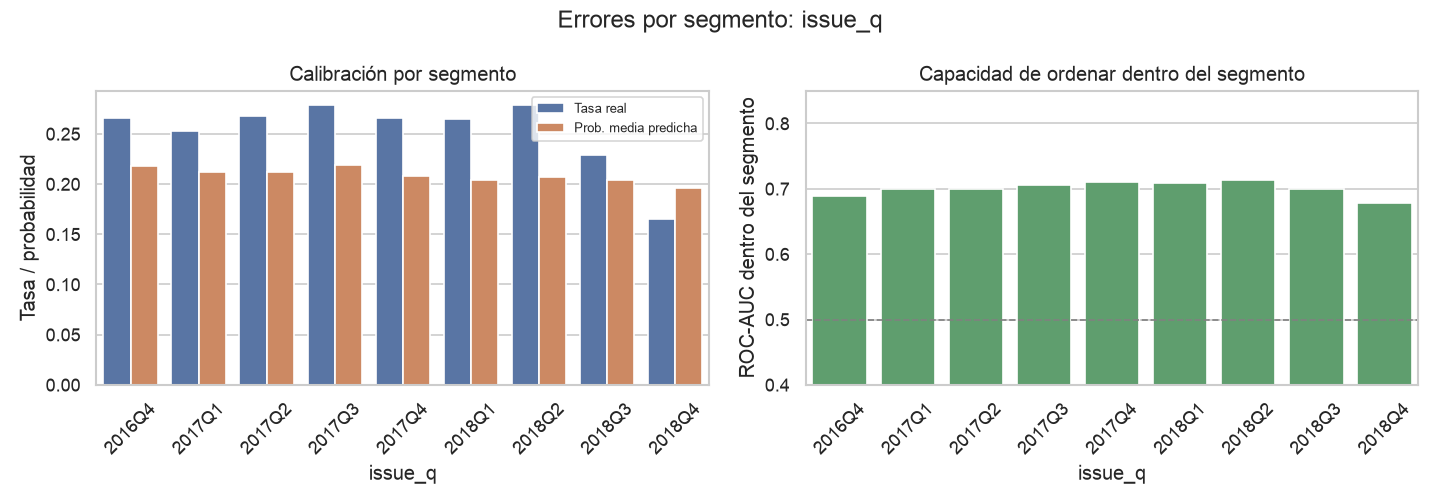

,ingreso_quintil,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,Q1 (bajo),57282,0.310,0.244,0.680,0.843,0.380,0.689,-0.066
1,Q2,65425,0.273,0.225,0.696,0.793,0.363,0.598,-0.048
2,Q3,46705,0.258,0.213,0.704,0.769,0.357,0.557,-0.046
3,Q4,54894,0.246,0.198,0.713,0.751,0.355,0.520,-0.048
4,Q5 (alto),55939,0.223,0.174,0.707,0.684,0.338,0.452,-0.049


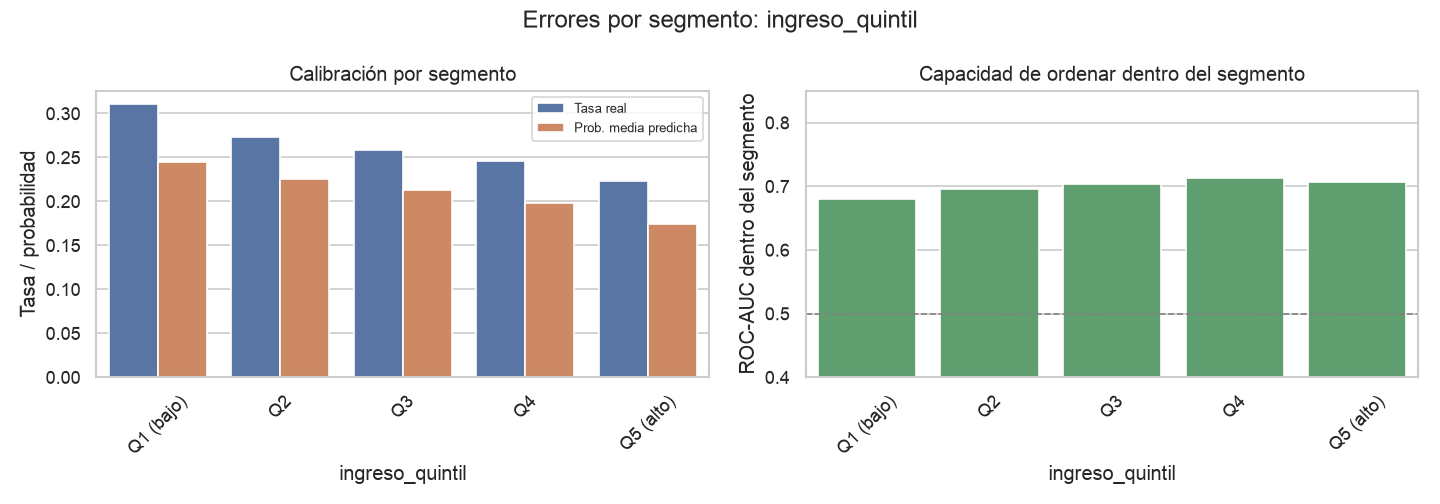

,home_ownership,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,MORTGAGE,139157,0.219,0.188,0.697,0.714,0.318,0.491,-0.031
1,OWN,34335,0.271,0.215,0.687,0.790,0.360,0.596,-0.057
2,RENT,106457,0.318,0.242,0.696,0.826,0.402,0.653,-0.076


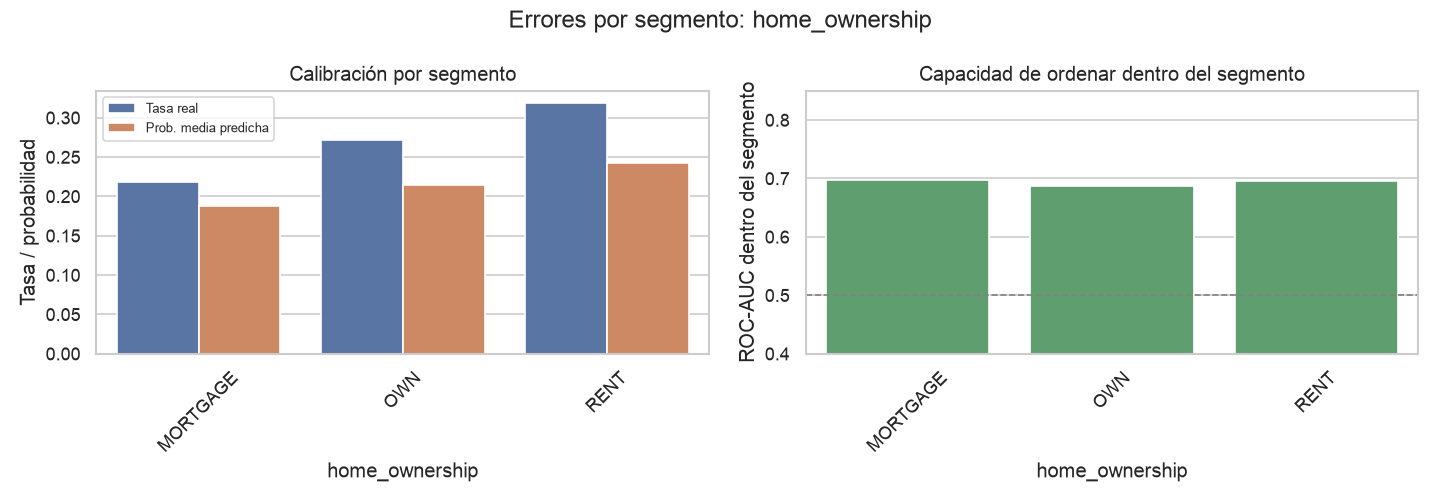

In [6]:
for s in ["grade", "issue_q", "ingreso_quintil", "home_ownership"]:
    display(seg_tables[s].style.format(precision=3).set_caption(s))
    display(Image(FIG / f"31_segment_{s}.png"))

,term,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,36 months,210371,0.229,0.168,0.700,0.676,0.342,0.452,-0.061
1,60 months,69874,0.366,0.343,0.659,0.962,0.389,0.905,-0.023


,verification_status,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,Not Verified,92889,0.202,0.168,0.715,0.653,0.325,0.406,-0.035
1,Source Verified,112145,0.267,0.215,0.687,0.780,0.352,0.590,-0.052
2,Verified,75211,0.333,0.262,0.675,0.862,0.396,0.725,-0.071


,emp_length,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,< 1 year,24508,0.284,0.219,0.688,0.777,0.374,0.590,-0.065
1,1 year,18618,0.278,0.218,0.702,0.793,0.372,0.592,-0.060
2,2 years,25827,0.269,0.211,0.698,0.766,0.363,0.567,-0.058
3,3 years,22865,0.272,0.210,0.707,0.774,0.373,0.563,-0.062
4,4 years,17274,0.266,0.210,0.699,0.762,0.362,0.560,-0.056
5,5 years,17171,0.260,0.208,0.703,0.769,0.360,0.555,-0.052
6,6 years,12286,0.249,0.207,0.715,0.778,0.352,0.549,-0.042
7,7 years,10023,0.256,0.206,0.698,0.750,0.352,0.544,-0.050
8,8 years,8838,0.257,0.212,0.703,0.774,0.353,0.564,-0.045
9,9 years,9297,0.243,0.210,0.721,0.794,0.344,0.560,-0.033


,purpose,n,tasa_default_real,prob_media_predicha,roc_auc,recall,precision,tasa_marcados,sesgo_calibracion
0,car,3421,0.195,0.164,0.737,0.689,0.326,0.411,-0.030
3,home_improvement,21966,0.229,0.180,0.712,0.703,0.346,0.465,-0.048
1,credit_card,53983,0.236,0.190,0.698,0.712,0.342,0.491,-0.046
10,vacation,2682,0.239,0.170,0.732,0.679,0.380,0.427,-0.069
4,house,2628,0.259,0.209,0.703,0.768,0.356,0.558,-0.050
5,major_purchase,7484,0.268,0.197,0.730,0.744,0.399,0.500,-0.071
8,other,22178,0.271,0.201,0.715,0.756,0.384,0.533,-0.070
2,debt_consolidation,155673,0.274,0.227,0.696,0.807,0.359,0.615,-0.047
6,medical,4522,0.277,0.199,0.696,0.748,0.384,0.539,-0.078
7,moving,2424,0.300,0.213,0.705,0.801,0.407,0.591,-0.088


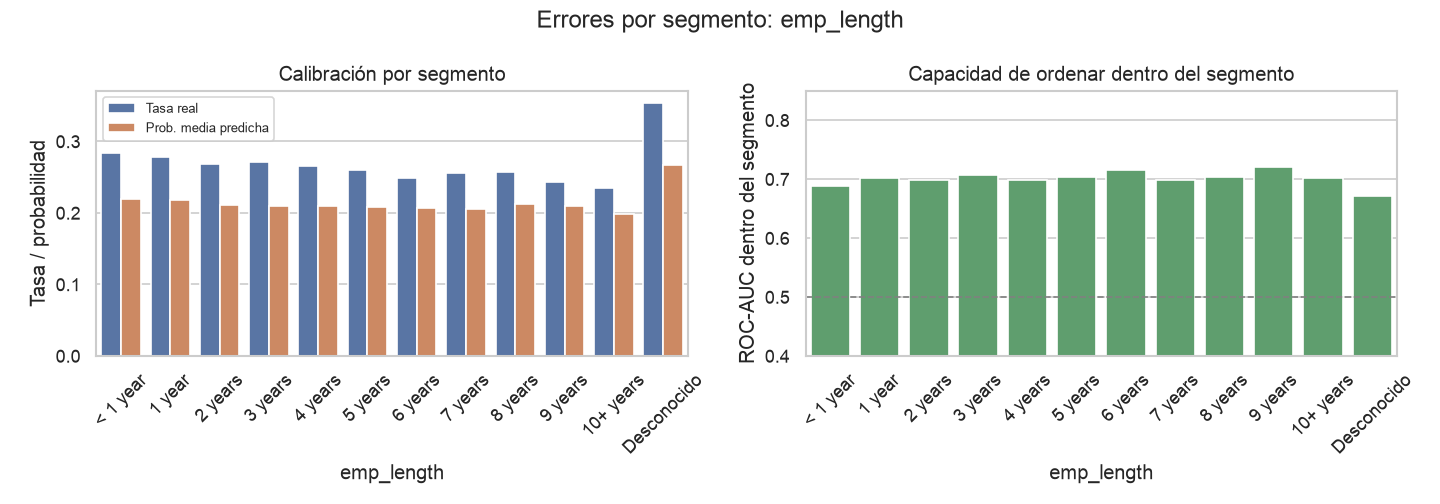

In [7]:
for s in ["term", "verification_status", "emp_length", "purpose"]:
    display(seg_tables[s].style.format(precision=3).set_caption(s))
display(Image(FIG / "31_segment_emp_length.png"))

**Lectura:**
- **El grade de Lending Club domina.** Dentro de cada grade, el AUC del modelo cae a **0.58–0.67**, contra 0.70 global. Gran parte de la capacidad de ordenar viene de reproducir el grade que asigna Lending Club. Al umbral operativo, el modelo casi no marca préstamos A (0.2%) y marca casi todos los C–G (80–100%). En la práctica, el umbral funciona como una regla por grade.
- **Subestimación sistemática.** En casi todos los segmentos, la probabilidad media predicha queda por debajo de la tasa real, con un sesgo de −2 a −9 puntos. Es más fuerte en `small_business` (−14.6), `emp_length = Desconocido` (−8.6), inquilinos `RENT` (−7.6), verificados `Verified` (−7.1) y el quintil de ingreso más bajo (−6.6). Esos son los grupos cuyo riesgo **más creció** entre el train y el test.
- **Deriva en el tiempo.** El AUC por trimestre del test es estable (0.68–0.71), así que la capacidad de ordenar no se degrada en 2 años. Lo que se degrada es la calibración. En 2018Q3–Q4, la tasa observada cae (16.5% en 2018Q4) por **sesgo de resolución**: de esos préstamos recientes solo se conocen los que terminaron rápido, muchos por pago anticipado.
- **Préstamos a 60 meses:** tienen más riesgo real (36.6% frente a 22.9%), el modelo los ordena peor (AUC 0.66 frente a 0.70) y marca al 90%.
- **Grupos de ingreso y vivienda:** el modelo marca más a inquilinos (65%) y a ingresos bajos (69%) que a propietarios con hipoteca (49%) o a ingresos altos (45%). Esto refleja diferencias reales en la tasa de default, pero tiene implicaciones de equidad que se discuten en la sección 5.

## 3. Interpretabilidad

### 3.1 Importancia por permutación (modelo final)

Se mide cuánto cae el ROC-AUC en el test al barajar cada variable (5
repeticiones, submuestra de 60 000 préstamos). Es agnóstica al modelo y se
calcula sobre datos no vistos.

In [8]:
from sklearn.inspection import permutation_importance

sub = preds.sample(n=min(60_000, len(preds)), random_state=RANDOM_SEED)
X_sub = to_model_frame(sub)
pi = permutation_importance(model, X_sub, sub[TARGET], scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_SEED, n_jobs=1)
imp = (pd.DataFrame({"variable": X_sub.columns, "caida_auc": pi.importances_mean,
                     "std": pi.importances_std})
       .sort_values("caida_auc", ascending=False))
imp.to_csv(OUT / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
t = imp.iloc[::-1]
ax.barh(t["variable"], t["caida_auc"], xerr=t["std"], color="#C44E52", capsize=3)
ax.set_xlabel("Caída de ROC-AUC al permutar la variable")
ax.set_title(f"Importancia por permutación — {ev.MODEL_LABELS[final_name]} (test)")
fig.tight_layout(); fig.savefig(FIG / "32_permutation_importance.png", dpi=120); plt.show()
imp.head(10)

/var/folders/x3/x63pd0m12l35bhc94445mwsw0000gn/T/ipykernel_14249/2213137650.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(FIG / "32_permutation_importance.png", dpi=120); plt.show()


,variable,caida_auc,std
16,sub_grade,0.0460,0.0005
0,loan_amnt,0.0125,0.0006
18,home_ownership,0.0094,0.0006
14,term,0.0087,0.0006
4,fico_avg,0.0082,0.0006
3,dti,0.0063,0.0005
17,emp_length,0.0057,0.0002
2,annual_inc,0.0043,0.0002
8,total_acc,0.0039,0.0001
15,grade,0.0032,0.0002


### 3.2 Efecto de las variables principales (dependencia parcial)

In [9]:
from sklearn.inspection import PartialDependenceDisplay

pd_vars = [v for v in ["int_rate", "fico_avg", "dti", "annual_inc", "loan_amnt",
                       "credit_hist_months"] if v in X_sub.columns]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
PartialDependenceDisplay.from_estimator(
    model, X_sub.sample(8000, random_state=RANDOM_SEED), pd_vars, ax=axes.ravel(),
    grid_resolution=30, percentiles=(0.02, 0.98), kind="average")
fig.suptitle("Dependencia parcial: efecto promedio sobre la probabilidad de default")
fig.tight_layout(); fig.savefig(FIG / "33_partial_dependence.png", dpi=120); plt.show()

/var/folders/x3/x63pd0m12l35bhc94445mwsw0000gn/T/ipykernel_14249/2827421303.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(FIG / "33_partial_dependence.png", dpi=120); plt.show()


### 3.3 Contraste con el modelo interpretable (regresión logística ajustada)

Coeficientes estandarizados: para numéricas, el efecto en log-odds de subir una
desviación estándar; para categóricas, frente al promedio de la codificación one-hot.

In [10]:
lr = joblib.load(OUT / "models" / "logreg_tuned.joblib")["model"]
names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#C44E52", "#55A868"))
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Coeficiente (log-odds)  → más riesgo")
ax.set_title("Regresión logística ajustada: 10 coeficientes más positivos y negativos")
fig.tight_layout(); fig.savefig(FIG / "34_logreg_coefficients.png", dpi=120); plt.show()

/var/folders/x3/x63pd0m12l35bhc94445mwsw0000gn/T/ipykernel_14249/579421674.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.savefig(FIG / "34_logreg_coefficients.png", dpi=120); plt.show()


**Lectura:**
- **Importancia por permutación:** `sub_grade` es de lejos la variable más importante (−0.046 de AUC al permutarla), seguida de `loan_amnt`, `home_ownership`, `term`, `fico_avg` y `dti`. `int_rate` y `grade` aparecen bajas **no porque no importen**, sino porque son casi redundantes con `sub_grade`: Lending Club fija la tasa según el sub-grade. Al permutar una de ellas, el modelo sigue teniendo la misma información en las otras. Con variables correlacionadas, la importancia por permutación se reparte y hay que leerla por grupos.
- **Dependencia parcial:** el riesgo **baja** con el FICO (de ≈0.24 a ≈0.16 entre 660 y 800) y con el ingreso hasta unos 100k. **Sube** con el DTI (sobre todo entre 10 y 30), con el monto y en los préstamos a 60 meses. La antigüedad crediticia casi no aporta una vez controlado lo demás. La forma no monótona de `int_rate` se explica porque su efecto ya está capturado por `sub_grade`.
- **Coherencia con el modelo lineal:** los coeficientes de la regresión logística apuntan en la misma dirección (más riesgo con sub-grades bajos, plazo de 60 meses, DTI e `inq_last_6mths`; menos riesgo con FICO alto y propósito `car`/`credit_card`). Los dos modelos aprenden relaciones económicamente sensatas, lo que da confianza en que no se apoyan en artefactos de los datos.

## 4. Casos problemáticos

In [11]:
# Falsos negativos "seguros": defaults a los que el modelo dio el score más bajo
# Falsos positivos "seguros": préstamos pagados con el score más alto
cols = ["score", "loan_status", "grade", "sub_grade", "int_rate", "fico_avg", "annual_inc",
        "dti", "loan_amnt", "term", "purpose", "emp_length", "home_ownership"]
fn_conf = preds[(y == 1)].nsmallest(10, "score")[cols]
fp_conf = preds[(y == 0)].nlargest(10, "score")[cols]
display(fn_conf.style.format(precision=3).set_caption("Defaults con score más bajo"))
display(fp_conf.style.format(precision=3).set_caption("Pagados con score más alto"))

,score,loan_status,grade,sub_grade,int_rate,fico_avg,annual_inc,dti,loan_amnt,term,purpose,emp_length,home_ownership
33744,0.014,Charged Off,A,A1,5.320,812.000,106000.000,6.530,5300.000,36 months,credit_card,10+ years,MORTGAGE
30455,0.014,Charged Off,A,A1,5.320,817.000,123000.000,4.420,15000.000,36 months,debt_consolidation,2 years,MORTGAGE
199252,0.014,Default,A,A1,5.320,817.000,120000.000,6.860,1675.000,36 months,car,< 1 year,MORTGAGE
257913,0.014,Charged Off,A,A1,5.310,792.000,95000.000,1.360,12000.000,36 months,debt_consolidation,10+ years,MORTGAGE
249130,0.018,Late (31-120 days),A,A1,5.310,772.000,110000.000,9.390,7000.000,36 months,debt_consolidation,10+ years,MORTGAGE
178246,0.018,Charged Off,A,A1,5.320,802.000,95000.000,16.000,6000.000,36 months,other,4 years,MORTGAGE
103064,0.018,Charged Off,A,A1,5.320,777.000,97000.000,5.310,10000.000,36 months,home_improvement,1 year,MORTGAGE
218482,0.018,Late (31-120 days),A,A1,5.320,812.000,150000.000,1.230,10000.000,36 months,debt_consolidation,< 1 year,MORTGAGE
108156,0.018,Charged Off,A,A1,5.320,767.000,166960.000,5.200,15500.000,36 months,home_improvement,7 years,MORTGAGE
209957,0.018,Charged Off,A,A1,5.320,842.000,65000.000,9.840,4500.000,36 months,credit_card,7 years,MORTGAGE


,score,loan_status,grade,sub_grade,int_rate,fico_avg,annual_inc,dti,loan_amnt,term,purpose,emp_length,home_ownership
176268,0.777,Fully Paid,F,F3,30.170,682.000,61000.000,31.280,15000.000,60 months,debt_consolidation,Desconocido,RENT
148269,0.770,Fully Paid,E,E5,26.300,672.000,24000.000,35.700,30000.000,60 months,debt_consolidation,Desconocido,RENT
111220,0.766,Fully Paid,F,F1,28.690,662.000,15120.000,37.901,18000.000,60 months,home_improvement,Desconocido,RENT
232653,0.763,Fully Paid,F,F1,28.720,677.000,42000.000,34.460,16000.000,60 months,debt_consolidation,10+ years,RENT
232059,0.755,Fully Paid,F,F3,30.170,677.000,23500.000,37.901,35000.000,60 months,debt_consolidation,10+ years,RENT
230129,0.753,Fully Paid,F,F5,30.750,667.000,23408.000,29.030,10900.000,60 months,debt_consolidation,Desconocido,RENT
210485,0.750,Fully Paid,G,G1,30.790,672.000,1000.000,37.901,20000.000,60 months,major_purchase,Desconocido,RENT
185333,0.746,Fully Paid,E,E5,26.300,672.000,1000.000,37.901,30000.000,60 months,debt_consolidation,Desconocido,RENT
210697,0.745,Fully Paid,E,E5,26.300,677.000,51864.000,37.901,20000.000,60 months,debt_consolidation,Desconocido,RENT
237247,0.740,Fully Paid,F,F4,30.650,692.000,46776.000,37.800,22050.000,60 months,credit_card,Desconocido,RENT


In [12]:
# Perfil medio de cada tipo de error frente a los aciertos
perfil_num = ["score", "int_rate", "fico_avg", "annual_inc", "dti", "loan_amnt",
              "revol_util", "inq_last_6mths", "credit_hist_months"]
perfil = preds.groupby("tipo")[perfil_num].median()
perfil["% 60 meses"] = preds.groupby("tipo")["term"].apply(lambda s: s.str.contains("60").mean())
perfil["% grade A-B"] = preds.groupby("tipo")["grade"].apply(lambda s: s.isin(["A", "B"]).mean())
perfil.loc[["VP", "FN", "FP", "VN"]]

,score,int_rate,fico_avg,annual_inc,dti,loan_amnt,revol_util,inq_last_6mths,credit_hist_months,% 60 meses,% grade A-B
tipo,,,,,,,,,,,
VP,0.2986,16.9100,682.0000,60000.0000,20.6500,15000.0000,51.0000,0.0000,164.9803,0.4305,0.0973
FN,0.1221,10.4900,702.0000,70000.0000,15.3600,10000.0000,42.9000,0.0000,181.9974,0.0591,0.7902
FP,0.2515,15.4900,687.0000,62000.0000,19.7800,14000.0000,48.2000,0.0000,168.0026,0.3818,0.1424
VN,0.0965,9.4400,712.0000,74800.0000,14.6200,10000.0000,35.1000,0.0000,185.0197,0.0534,0.8485


**Lectura:**
- Los **falsos negativos** son, en su mayoría, préstamos que lucían de bajo riesgo: el 79% es grade A–B, solo el 6% es a 60 meses, con tasa mediana de 10.5% y FICO de 702. Su perfil es casi idéntico al de los verdaderos negativos (85% A–B, FICO 712). Con la información disponible al originar, **son indistinguibles** de los buenos pagadores. Probablemente los causan eventos posteriores, como pérdida de empleo o problemas de salud, que ninguna variable de originación puede anticipar.
- Los **falsos positivos** se parecen a los verdaderos positivos: tasa de 15.5%, 38% a 60 meses, solo 14% A–B. Son préstamos de riesgo real que terminaron pagándose. Para el modelo eso es una diferencia de suerte, no un error que se pueda corregir.
- Esto refuerza la conclusión del notebook 03: el límite de ≈0.70 de AUC está en **la información disponible al originar**. Mejorarlo exigiría nuevas fuentes de datos (historial de pagos, buró más detallado, datos de empleo verificados), no otro algoritmo.

## 5. Riesgos éticos, sesgos y limitaciones

**Sesgos de los datos**
- **Sesgo de selección (*reject inference*):** solo se observan préstamos que Lending Club **aprobó**. El modelo aprende el riesgo *condicionado a la política de aprobación de LC* y no puede generalizar a los solicitantes rechazados, que serían justamente los de mayor riesgo.
- **Sesgo de resolución:** al excluir los préstamos `Current`, los periodos recientes sobrerrepresentan los préstamos que terminaron pronto. Por eso la tasa de default del test (26.3%) es más alta que la del train (19.9%) y la de 2018Q4 es atípicamente baja. Las cifras de calibración del test deben leerse con esa cautela.
- **Deriva temporal:** la tasa de default por trimestre varía entre ~12% y ~28%, y la política de crédito de LC cambió con los años. El modelo ordena bien en 2017–2018, pero subestima el riesgo en ≈5 puntos.

**Riesgos de equidad**
- El dataset no incluye atributos protegidos (raza, género, edad), así que no se puede auditar la equidad directamente. Pero `home_ownership`, el ingreso, `emp_length` y el propósito pueden actuar como **proxies** de grupos socioeconómicos. El modelo marca al 65% de los inquilinos frente al 49% de los propietarios con hipoteca, y al 69% del quintil de ingreso bajo frente al 45% del alto.
- Esas diferencias **reflejan tasas reales de default distintas**, no un sesgo introducido por el modelo. Aun así, una política basada en él restringiría de forma desproporcionada el crédito a grupos de menores recursos. Además, el modelo **subestima más** el riesgo justamente en esos grupos, lo que podría trasladar pérdidas a los inversionistas.
- `emp_length = Desconocido` es un caso de **ausencia informativa**: no reportar la antigüedad laboral se asocia a 35% de default. Penalizar la falta de un dato puede afectar a trabajadores independientes o informales.
- `addr_state` se excluyó deliberadamente (alta cardinalidad y riesgo de discriminación geográfica / *redlining*).

**Limitaciones**
- Ingresos y empleo son **autodeclarados** y solo verificados en parte.
- El modelo depende fuertemente del `sub_grade` de LC, que es la salida de otro modelo de riesgo. En gran medida, el modelo *refina* el scoring de LC en vez de reemplazarlo.
- No se modeló la **pérdida esperada** (cuánto se recupera tras el default) ni el momento del default. Un préstamo que falla en el mes 30 no cuesta lo mismo que uno que falla en el mes 2.
- El umbral maximiza F1 y no los costos reales de negocio.